# Narrative Mirror — Pilot 2: divergence, summaries and Q&A with Qwen2.5-1.5B

**What this is:** a prototype pipeline. For each short text it (1) compares a model trajectory with author-assigned sentence salience, (2) asks the model for a summary and checks which sentences survive, and (3) asks questions that target specific sentences.

**Texts:** flower pots (memoir, 15 sentences), pomelo / Taqwa (memoir, 35), a legal contract (6), a medical record (6). Salience scores (0–1) were assigned by the author.

**Models:** Qwen2.5-1.5B (hidden states) and Qwen2.5-1.5B-Instruct (summaries and answers); all-MiniLM-L6-v2 for the coverage check.

**How to run:** Colab, CPU is enough. Run one text cell (1–4), then the pipeline cells.

**Important:** `data`, `full_text` and `questions` are overwritten by each text cell. The outputs saved in this notebook come from the **last text run, the medical record**. Outputs for the other texts were recorded separately and are summarized in `results.md`.

**Known issues:**
- Sentences are encoded one at a time, without context, and the trajectory is a projection onto the first-to-last sentence direction, which largely reflects position.
- The coverage check marked the medical "hopelessness" sentence as dropped (similarity 0.295), although the summary contains it.
- n = 6 for the medical correlation (r = 0.65): not a reliable result on its own; see `results.md` for all texts.


## 1. Text: flower pots (memoir)


In [ ]:
data = [
    {'idx': 0, 'text': 'Later that week, I drove my aunt to the supermarket.', 'salience': 0.05},
    {'idx': 1, 'text': "I couldn't find a parking spot, so I waited in the car near a private house's parking.", 'salience': 0.1},
    {'idx': 2, 'text': 'I knew the owners-two young sisters who had just lost their mum.', 'salience': 0.85},
    {'idx': 3, 'text': "I knew they wouldn't mind.", 'salience': 0.15},
    {'idx': 4, 'text': 'Still, I kept glancing around, checking if they were home, if they could see me.', 'salience': 0.25},
    {'idx': 5, 'text': 'I felt like I was intruding.', 'salience': 0.3},
    {'idx': 6, 'text': 'After a while, I saw my aunt in the mirror, walking back with shopping bags.', 'salience': 0.1},
    {'idx': 7, 'text': 'I felt relieved.', 'salience': 0.15},
    {'idx': 8, 'text': 'Just before she reached the car, my eyes caught the corner of their parking space.', 'salience': 0.35},
    {'idx': 9, 'text': 'A few large flower pots stood there.', 'salience': 0.4},
    {'idx': 10, 'text': 'Neglected. Dry soil. The flowers had died, it looked like ashes.', 'salience': 0.85},
    {'idx': 11, 'text': 'For a moment, a thought passed-almost judgment.', 'salience': 0.5},
    {'idx': 12, 'text': "But it didn't stay.", 'salience': 0.6},
    {'idx': 13, 'text': 'It was replaced, quietly, by something else.', 'salience': 0.75},
    {'idx': 14, 'text': 'Compassion.', 'salience': 0.95}
]




list

## 2. Text: pomelo / Taqwa (memoir)


In [ ]:
data = [
    {'idx': 0, 'text': 'As a child, I wanted money for one thing only: sweets.', 'salience': 0.10},
    {'idx': 1, 'text': 'The latest ones at the village supermarket—those brightly wrapped treasures lined like jewels on the shelf.', 'salience': 0.10},
    {'idx': 2, 'text': 'Eid was my payday.', 'salience': 0.15},
    {'idx': 3, 'text': 'Dressed in fresh clothes and armed with a sense of entitlement only children possess, we roamed the village from house to house, palms open, smiles wide.', 'salience': 0.15},
    {'idx': 4, 'text': 'No one owed us a thing, but it was a day designed to delight children, and we never questioned it.', 'salience': 0.20},
    {'idx': 5, 'text': 'Relatives were the big banks—where bonuses dropped like gold coins.', 'salience': 0.10},
    {'idx': 6, 'text': "By midday, our pockets sagged with clinking change, and by evening we'd collapse on our beds, emptying wallets onto the blanket in gleeful chaos.", 'salience': 0.10},
    {'idx': 7, 'text': "We'd count, sort, and then guard that stash as if it were sacred.", 'salience': 0.15},
    {'idx': 8, 'text': 'That treasure would fund our candy runs for months.', 'salience': 0.10},
    {'idx': 9, 'text': "There was a secret shortcut to the candy store that only the neighbourhood kids knew—a narrow path threading through someone's private garden.", 'salience': 0.25},
    {'idx': 10, 'text': 'And in that garden stood a pomelo tree, its fruits impossibly large, suspended like golden moons.', 'salience': 0.35},
    {'idx': 11, 'text': 'They called to us.', 'salience': 0.30},
    {'idx': 12, 'text': 'We never dared pluck them, but the temptation lingered, sweet and sticky like the candies we craved.', 'salience': 0.40},
    {'idx': 13, 'text': 'Months later, near the end of my stash, I passed by alone.', 'salience': 0.45},
    {'idx': 14, 'text': 'The fruit still hung there, ripe with allure.', 'salience': 0.35},
    {'idx': 15, 'text': 'I reached out, just to touch.', 'salience': 0.55},
    {'idx': 16, 'text': 'My fingers closed around one.', 'salience': 0.60},
    {'idx': 17, 'text': "And then a voice—a woman's voice—startled me.", 'salience': 0.65},
    {'idx': 18, 'text': "She'd seen everything.", 'salience': 0.70},
    {'idx': 19, 'text': 'She asked me to open my hand.', 'salience': 0.80},
    {'idx': 20, 'text': 'I did.', 'salience': 0.60},
    {'idx': 21, 'text': "She didn't yell.", 'salience': 0.45},
    {'idx': 22, 'text': "She didn't scold.", 'salience': 0.45},
    {'idx': 23, 'text': 'She simply took the last coins I had and walked away.', 'salience': 0.85},
    {'idx': 24, 'text': 'That day, something shifted in me.', 'salience': 0.75},
    {'idx': 25, 'text': "It wasn't about the money, nor the fruit.", 'salience': 0.65},
    {'idx': 26, 'text': "It was the first time I've been treated like an adult, by an adult.", 'salience': 0.80},
    {'idx': 27, 'text': 'Paying the price for a crime.', 'salience': 0.70},
    {'idx': 28, 'text': 'I realised not everything comes free.', 'salience': 0.75},
    {'idx': 29, 'text': 'I think that was my first real lesson in accountability.', 'salience': 0.85},
    {'idx': 30, 'text': 'In the unseen moral lines that exist even when no one else is watching.', 'salience': 0.90},
    {'idx': 31, 'text': 'That moment planted a seed in me.', 'salience': 0.80},
    {'idx': 32, 'text': "I'm being watched always.", 'salience': 0.85},
    {'idx': 33, 'text': 'I lost coins but gained compass.', 'salience': 0.90},
    {'idx': 34, 'text': 'Taqwa.', 'salience': 0.95},
]


## 3. Text: legal contract, with questions


In [ ]:
# Legal contract
data = [
    {'idx': 0, 'text': 'The borrower agrees to repay the principal amount of $500,000 over a period of 10 years.', 'salience': 0.30},
    {'idx': 1, 'text': 'Monthly payments shall be made on the first business day of each month.', 'salience': 0.20},
    {'idx': 2, 'text': 'The interest rate is fixed at 4.5% per annum for the duration of the loan.', 'salience': 0.30},
    {'idx': 3, 'text': 'Early repayment of the loan carries a penalty of 3% of the outstanding balance.', 'salience': 0.85},
    {'idx': 4, 'text': 'The borrower must maintain a minimum account balance of $50,000 at all times.', 'salience': 0.75},
    {'idx': 5, 'text': 'Failure to maintain the minimum balance constitutes a breach of covenant.', 'salience': 0.90},
]

full_text = """
The borrower agrees to repay the principal amount of $500,000 over a period of 10 years. Monthly payments shall be made on the first business day of each month. The interest rate is fixed at 4.5% per annum for the duration of the loan. Early repayment of the loan carries a penalty of 3% of the outstanding balance. The borrower must maintain a minimum account balance of $50,000 at all times. Failure to maintain the minimum balance constitutes a breach of covenant.
"""

questions = [
    {"q": "Can the borrower repay the loan early without any consequences?",
     "target_idx": 3, "salience": 0.85},
    {"q": "What happens if the borrower's account drops below $50,000?",
     "target_idx": 5, "salience": 0.90},
    {"q": "What is the interest rate?",
     "target_idx": 2, "salience": 0.30},
]



## 4. Text: medical record, with questions


In [ ]:
# Medical record
data = [
    {'idx': 0, 'text': 'Patient is a 45-year-old female presenting with recurring headaches over the past two weeks.', 'salience': 0.30},
    {'idx': 1, 'text': 'She reports the headaches are worse in the morning and improve throughout the day.', 'salience': 0.40},
    {'idx': 2, 'text': 'She has a documented allergy to penicillin and sulfa drugs.', 'salience': 0.85},
    {'idx': 3, 'text': 'Current medications include lisinopril 10mg daily for hypertension.', 'salience': 0.60},
    {'idx': 4, 'text': 'She mentioned feeling increasingly hopeless and having difficulty sleeping.', 'salience': 0.95},
    {'idx': 5, 'text': 'Physical examination reveals blood pressure of 138/88 and normal neurological findings.', 'salience': 0.30},
]

full_text = """
Patient is a 45-year-old female presenting with recurring headaches over the past two weeks. She reports the headaches are worse in the morning and improve throughout the day. She has a documented allergy to penicillin and sulfa drugs. Current medications include lisinopril 10mg daily for hypertension. She mentioned feeling increasingly hopeless and having difficulty sleeping. Physical examination reveals blood pressure of 138/88 and normal neurological findings.
"""

questions = [
    {"q": "Is it safe to prescribe amoxicillin to this patient?",
     "target_idx": 2, "salience": 0.85},
    {"q": "Are there any mental health concerns mentioned in the record?",
     "target_idx": 4, "salience": 0.95},
    {"q": "What is the patient's blood pressure?",
     "target_idx": 5, "salience": 0.30},
]

## 5. Keep text and salience


In [ ]:
extracted_data = []
for item in data:
    extracted_data.append({
        'text': item['text'],
        'salience': item['salience']
    })

type(extracted_data)

list

## 6. Install


In [ ]:
!pip install transformers torch

## 7. Load Qwen2.5-1.5B with hidden states


In [ ]:
from transformers import AutoModel, AutoTokenizer
import torch

model_name = "Qwen/Qwen2.5-1.5B"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name, output_hidden_states=True)
model.eval()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen2Model(
  (embed_tokens): Embedding(151936, 1536)
  (layers): ModuleList(
    (0-27): 28 x Qwen2DecoderLayer(
      (self_attn): Qwen2Attention(
        (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
        (k_proj): Linear(in_features=1536, out_features=256, bias=True)
        (v_proj): Linear(in_features=1536, out_features=256, bias=True)
        (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
      )
      (mlp): Qwen2MLP(
        (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
        (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
        (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
        (act_fn): SiLUActivation()
      )
      (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
    )
  )
  (norm): Qwen2RMSNorm((1536,), eps=1e-06)
  (rotary_emb): Qwen2RotaryEmbedding()
)

## 8. Sentences and salience lists


In [ ]:
sentences = [item['text'] for item in extracted_data]
salience_scores = [item['salience'] for item in extracted_data]

## 9. Sentence vectors
Each sentence encoded on its own; mean-pooled last layer.


In [ ]:


all_sentence_vectors = []

for sentence in sentences:
    inputs = tokenizer(sentence, return_tensors="pt")

    with torch.no_grad():
        outputs = model(**inputs)

    last_layer = outputs.hidden_states[-1]          # shape: [1, tokens, hidden_dim]
    sentence_vector = last_layer.mean(dim=1)        # shape: [1, hidden_dim]

    all_sentence_vectors.append(sentence_vector.squeeze().float().numpy())


## 10. Model trajectory and divergence
Projection onto the S1→Sn direction, normalized 0–1; divergence = |trajectory − salience|.


In [ ]:
import numpy as np

# Project all sentence vectors onto S1→Sn direction
vectors = np.stack(all_sentence_vectors)
direction = vectors[-1] - vectors[0]
direction = direction / np.linalg.norm(direction)

trajectory = []
for v in vectors:
    proj = np.dot(v - vectors[0], direction)
    trajectory.append(proj)

# Normalize to 0-1
trajectory = np.array(trajectory)
trajectory = (trajectory - trajectory.min()) / (trajectory.max() - trajectory.min())

# Compare against your salience scores
divergence = np.abs(trajectory - salience_scores)

## 11. Plot: model trajectory vs human salience


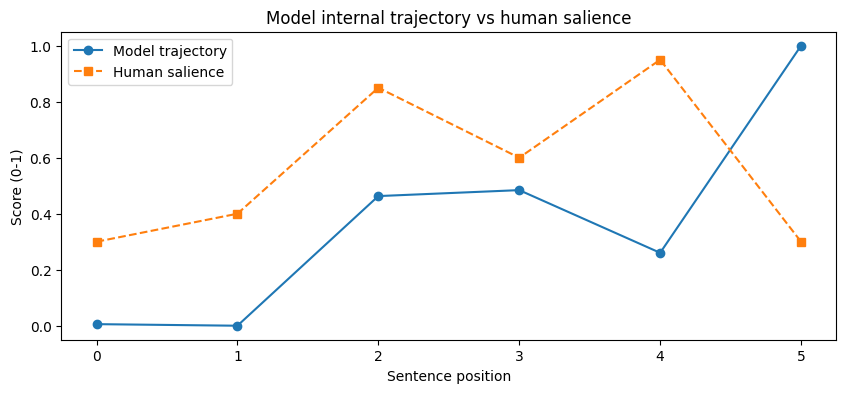

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(trajectory, 'o-', label='Model trajectory')
plt.plot(salience_scores, 's--', label='Human salience')
plt.xlabel('Sentence position')
plt.ylabel('Score (0-1)')
plt.title('Model internal trajectory vs human salience')
plt.legend()
plt.savefig('divergence_plot.png')

## 12. Summary, coverage check and correlation
Qwen2.5-1.5B-Instruct writes a 1-sentence summary; each sentence's similarity to the summary gives preserved / partial / dropped; correlation with divergence.


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from sentence_transformers import SentenceTransformer, util
import torch
import pandas as pd
import numpy as np


full_text1 = """
Later that week, I drove my aunt to the supermarket.
I couldn't find a parking spot, so I waited in the car near a private house's parking.
I knew the owners—two young sisters who had just lost their mum.
I knew they wouldn't mind.
Still, I kept glancing around, checking if they were home, if they could see me.
I felt like I was intruding.
After a while, I saw my aunt in the mirror, walking back with shopping bags.
I felt relieved.
Just before she reached the car, my eyes caught the corner of their parking space.
A few large flower pots stood there.
Neglected. Dry soil. The flowers had died, it looked like ashes.
For a moment, a thought passed—almost judgment.
But it didn't stay.
It was replaced, quietly, by something else.
Compassion.
"""

full_text1 = """
As a child, I wanted money for one thing only: sweets. The latest ones at the village supermarket—those brightly wrapped treasures lined like jewels on the shelf. Eid was my payday. Dressed in fresh clothes and armed with a sense of entitlement only children possess, we roamed the village from house to house, palms open, smiles wide. No one owed us a thing, but it was a day designed to delight children, and we never questioned it.
Relatives were the big banks—where bonuses dropped like gold coins. By midday, our pockets sagged with clinking change, and by evening we'd collapse on our beds, emptying wallets onto the blanket in gleeful chaos. We'd count, sort, and then guard that stash as if it were sacred. That treasure would fund our candy runs for months.
There was a secret shortcut to the candy store that only the neighbourhood kids knew—a narrow path threading through someone's private garden. And in that garden stood a pomelo tree, its fruits impossibly large, suspended like golden moons. They called to us. We never dared pluck them, but the temptation lingered, sweet and sticky like the candies we craved.
Months later, near the end of my stash, I passed by alone. The fruit still hung there, ripe with allure. I reached out, just to touch. My fingers closed around one. And then a voice—a woman's voice—startled me. She'd seen everything. She asked me to open my hand. I did. She didn't yell. She didn't scold. She simply took the last coins I had and walked away.
That day, something shifted in me. It wasn't about the money, nor the fruit. It was the first time I've been treated like an adult, by an adult. Paying the price for a crime. I realised not everything comes free. I think that was my first real lesson in accountability. In the unseen moral lines that exist even when no one else is watching. That moment planted a seed in me. I'm being watched always. I lost coins but gained compass. Taqwa.
"""

divergence = np.abs(trajectory - salience_scores)

print(len(sentences), len(salience_scores), len(divergence))

# -------------------------
# 2. Generate summary
# -------------------------

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float32
)
model.eval()

prompt = f"""
Summarize the following text in 1 sentence:

{full_text}
"""

messages = [
    {"role": "user", "content": prompt}
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=80,
        do_sample=False
    )

summary = tokenizer.decode(
    output_ids[0][inputs["input_ids"].shape[-1]:],
    skip_special_tokens=True
)

print("SUMMARY:")
print(summary)

# -------------------------
# 3. Check sentence coverage
# -------------------------

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

summary_emb = embedder.encode(summary, convert_to_tensor=True)

rows = []

for i, sentence in enumerate(sentences):
    sent_emb = embedder.encode(sentence, convert_to_tensor=True)
    similarity = util.cos_sim(sent_emb, summary_emb).item()

    # Simple rule:
    # high similarity = preserved
    # low similarity = dropped
    if similarity >= 0.55:
        status = "preserved"
        dropped = 0
    elif similarity >= 0.35:
        status = "partial"
        dropped = 0.5
    else:
        status = "dropped"
        dropped = 1

    rows.append({
        "sentence_id": i + 1,
        "sentence": sentence,
        "divergence": divergence[i],
        "coverage_similarity": round(similarity, 3),
        "coverage_status": status,
        "drop_score": dropped
    })

df = pd.DataFrame(rows)

print("\nCOVERAGE CHECK:")
display(df)

# -------------------------
# 4. Correlation
# -------------------------

corr = df["divergence"].corr(df["drop_score"])

print("\nCorrelation between divergence and drop_score:")
print(round(corr, 3))


6 6 6


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

SUMMARY:
A 45-year-old woman with a history of penicillin and sulfa allergies presents with worsening morning headaches that improve during the day, accompanied by feelings of hopelessness and insomnia, despite being on lisinopril for hypertension.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



COVERAGE CHECK:


,sentence_id,sentence,divergence,coverage_similarity,coverage_status,drop_score
0,1,Patient is a 45-year-old female presenting wit...,0.294372,0.503,partial,0.5
1,2,She reports the headaches are worse in the mor...,0.400000,0.612,preserved,0.0
2,3,She has a documented allergy to penicillin and...,0.386990,0.543,partial,0.5
3,4,Current medications include lisinopril 10mg da...,0.115724,0.528,partial,0.5
4,5,She mentioned feeling increasingly hopeless an...,0.689647,0.295,dropped,1.0
5,6,Physical examination reveals blood pressure of...,0.700000,0.184,dropped,1.0



Correlation between divergence and drop_score:
0.65


## 13. Question sets for the two memoir texts


In [ ]:
questions1 = [
    {"q": "Why were the flowers neglected?",
     "target_idx": 2, "divergence": divergence[2]},
    {"q": "What emotion did the narrator ultimately feel?",
     "target_idx": 14, "divergence": divergence[14]},
    {"q": "What did the dead flowers look like?",
     "target_idx": 10, "divergence": divergence[10]},
    {"q": "Was the narrator driving alone?",
     "target_idx": 0, "divergence": divergence[0]},
    {"q": "Did the narrator feel comfortable parking there?",
     "target_idx": 5, "divergence": divergence[5]}
]

questions2 = [
    {"q": "Why did the woman take the child's coins?",
     "target_idx": 23, "salience": 0.85},
    {"q": "What lesson did the narrator learn from this experience?",
     "target_idx": 29, "salience": 0.85},
    {"q": "What does Taqwa mean in this context?",
     "target_idx": 34, "salience": 0.95},
    {"q": "What did the children collect money for during Eid?",
     "target_idx": 0, "salience": 0.10},
    {"q": "Did the children ever pick the pomelos before this incident?",
     "target_idx": 12, "salience": 0.40},
    {"q": "Why didn't the woman yell or scold the child? What was the significance of her quiet response?",
 "target_idx": 26, "salience": 0.80}
]


## 14. Q&A
Answers the questions of the last text loaded (medical in this saved run).


In [ ]:





for qa in questions:
    prompt = f"Based on this text:\n{full_text}\n\nAnswer in one sentence: {qa['q']}"

    messages = [{"role": "user", "content": prompt}]
    text_input = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text_input, return_tensors="pt")

    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=60, do_sample=False)

    answer = tokenizer.decode(output_ids[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True)

    print(f"\nQ: {qa['q']}")
    print(f"A: {answer}")
    #print(f"Target sentence divergence: {qa['divergence']:.3f}")
    print("---")





Q: Is it safe to prescribe amoxicillin to this patient?
A: It is not safe to prescribe amoxicillin to this patient due to her known allergy to penicillin and sulfa drugs.
---

Q: Are there any mental health concerns mentioned in the record?
A: Yes, the patient mentions feeling increasingly hopeless and having difficulty sleeping, which could indicate potential mental health concerns.
---

Q: What is the patient's blood pressure?
A: The patient's blood pressure is 138/88.
---
